## IAPUCP - Modelos IA
### Redes Neuronales Convolucionales

In [17]:
# Importo librerias
import torch
import torchvision
import torchvision.transforms as transforms
import requests
from io import BytesIO


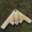

In [18]:
# Abro la imagen con la libreria PIL
from PIL import Image

response = requests.get('https://onetwork.org/dataset/0006.png')
img = Image.open(BytesIO(response.content))
#img = Image.open('images/0006.png')
img

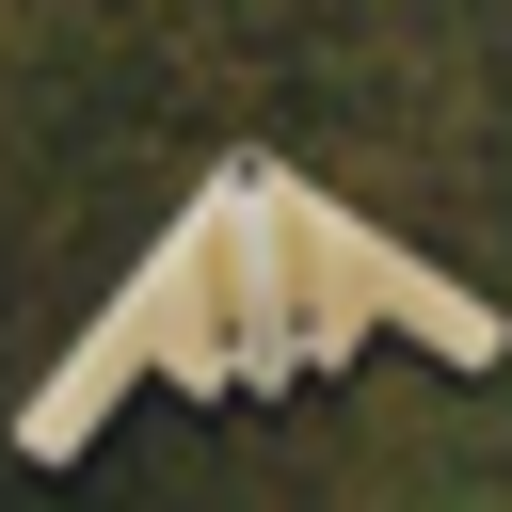

In [19]:
# Se hace un zoom a la imagen
img_zoom = img.resize((512,512))
img_zoom

In [20]:
# Abro una imagen con la libreria matplotlib
# Nuestro el valor de cada pixel en una matriz

# guardo la imagen temporalmente
with open('0006.png', 'wb') as f:
    f.write(response.content)

import matplotlib.pyplot as plt
image = plt.imread('0006.png')

# Muestro el primer pixel de la imagen en una matriz, donde cada pixel es un valor RGB
print(image[0][0])


[0.3254902  0.2901961  0.17254902]


In [21]:
# Muestro el pixel central de la imagen en una matriz, donde cada pixel es un valor RGB
print(image[16][16])

[0.7529412  0.7411765  0.65882355]


### Cada pixel de la imagen a una neurona
![Texto alternativo](https://onetwork.org/dataset/cnn_input.png)

### CIFAR10 Dataset
- 10 clases
- Imagenes de 32 x 32

In [22]:
# Se aplica transformaciones a las imagenes
# Se normaliza las imagenes con media y desviacion estandar
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 4

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

In [23]:
# Imprimo el tamño del conjunto de entrenamiento y de test
print("El tamaño del conjunto de entrenamiento es: ", len(trainset))
print("El tamaño del conjunto de test es: ", len(testset))

El tamaño del conjunto de entrenamiento es:  50000
El tamaño del conjunto de test es:  10000


In [24]:
# Definimos los tamaños deseados
train_limit = 2000
test_limit = 500

# Creamos subconjuntos tomando los primeros índices de cada dataset
train_indices = range(train_limit)
test_indices = range(test_limit)

trainset_limited = torch.utils.data.Subset(trainset, train_indices)
testset_limited = torch.utils.data.Subset(testset, test_indices)

# Reemplazamos los loaders para que usen los conjuntos limitados
batch_size = 4

trainloader = torch.utils.data.DataLoader(trainset_limited, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testloader = torch.utils.data.DataLoader(testset_limited, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

# Verificamos los nuevos tamaños
print("Nuevo tamaño de entrenamiento:", len(trainset_limited))
print("Nuevo tamaño de test:", len(testset_limited))

Nuevo tamaño de entrenamiento: 2000
Nuevo tamaño de test: 500


In [25]:
# Obtengo las 10 clases del dataset CIFAR10
classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

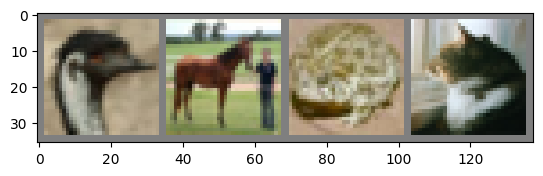

 bird horse  frog   cat


In [26]:
# Se muestra las imagenes de un batch del conjunto de datos
import matplotlib.pyplot as plt
import numpy as np

# Funcion para mostrar una imagen
def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# Obtengo imagenes de un batch
dataiter = iter(trainloader)
images, labels = next(dataiter)

# Muestro imagenes
imshow(torchvision.utils.make_grid(images))
# Se muestra las etiquetas
print(' '.join('%5s' % classes[labels[j]] for j in range(batch_size)))

## Red Neuronal Convolucional

In [27]:
# Se implementa una red neurnoal convolucional de 3 capas convolucionales y 2 capas neuronales
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 16 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x
    


In [28]:
# Se crea una instancia de la red
net = Net()

In [29]:
# Se define la funcion de perdida y el optimizador
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

In [30]:
# Se entrena la red en la tarjeta grafica
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

net.to(device)

cuda:0


Net(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [31]:
epochs = 5  #
losses = []
accuracies = []

for epoch in range(epochs):
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    net.train() # Aseguramos que el modelo esté en modo entrenamiento
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()

        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # Acumular la pérdida
        running_loss += loss.item()
        
        # Calcular aciertos para el accuracy de entrenamiento
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    # Métricas al finalizar la época
    epoch_loss = running_loss / len(trainloader)
    epoch_accuracy = 100 * correct_train / total_train
    
    losses.append(epoch_loss)
    accuracies.append(epoch_accuracy)
    
    print(f'Epoch [{epoch + 1}/{epochs}] ---> Loss: {epoch_loss:.3f} | Accuracy (Train): {epoch_accuracy:.2f}%')

print('Finished Training')

Epoch [1/5] ---> Loss: 2.301 | Accuracy (Train): 11.75%
Epoch [2/5] ---> Loss: 2.249 | Accuracy (Train): 18.00%
Epoch [3/5] ---> Loss: 2.074 | Accuracy (Train): 22.00%
Epoch [4/5] ---> Loss: 1.963 | Accuracy (Train): 26.00%
Epoch [5/5] ---> Loss: 1.853 | Accuracy (Train): 30.60%
Finished Training


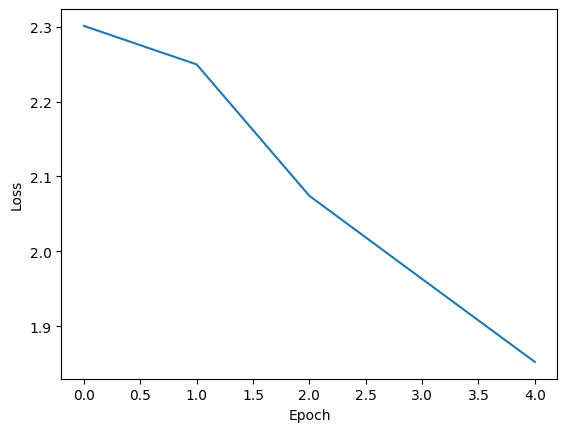

In [32]:
# Grafico el loss del entrenamiento
import matplotlib.pyplot as plt
plt.plot(losses)
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.show()

In [33]:
# Se guarda el estado del modelo entrenado
PATH = 'cifar_net.pth'
torch.save(net.state_dict(), PATH)
print("¡Modelo guardado exitosamente!")

¡Modelo guardado exitosamente!


In [34]:
# Verifico en el conjunto de datos de prueba la metrica de accuracy
correct = 0
total = 0
with torch.no_grad():
    for data in testloader:
        images, labels = data[0].to(device), data[1].to(device)
        outputs = net(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print('Accuracy of the network on test images: %d %%' % ( 100 * correct / total))

Accuracy of the network on test images: 26 %


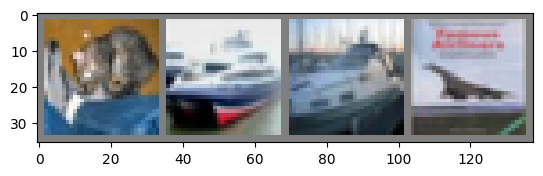

GroundTruth:    cat  ship  ship plane
Predicted:    dog   car   car  ship


In [35]:
# Obtener un batch de imágenes
dataiter = iter(testloader)
images, labels = next(dataiter)

# Mover los datos a la GPU si el modelo está en la GPU
images, labels = images.to(device), labels.to(device)

# Mostrar imágenes
imshow(torchvision.utils.make_grid(images.cpu()))  # Mover imágenes de vuelta a la CPU para mostrarlas
print('GroundTruth: ', ' '.join('%5s' % classes[labels[j]] for j in range(len(labels))))

# Obtener las predicciones del modelo
outputs = net(images)
_, predicted = torch.max(outputs, 1)

print('Predicted: ', ' '.join('%5s' % classes[predicted[j]] for j in range(len(predicted))))